> Paths here point at a flat working folder (`generated_sequences/`, `dna/`,
> `pdbqt/`, `output/`, `template/`), not at this repo's layout. The folders under
> `data/` use the same names, so copy them into one folder to re-run. See
> `docs/RERUN.md`.
>
> Code cells and stored outputs are as they were run. Only markdown was fixed
> where it contradicted the code.


# Stage 1 — Candidate dsDNA Sequence Generation

**Project:** DNA-based electrochemical sensor for IQS (quorum sensing molecule)  
**Goal:** Generate 10,000 candidate single-strand sequences that pass basic quality rules  
**Output:** Saved as CSV in `./generated_sequences/stage1_candidates.csv`

---
### What this notebook does:
1. Randomly generates DNA sequences (12–22 bases)
2. Applies 5 hard filters (length, GC content, homopolymer, base dominance, palindrome)
3. Saves all passing sequences with their basic properties to CSV
4. Shows summary statistics and plots

## Cell 1 — Import Libraries

In [1]:
import random
import os
import csv
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Cell 2 — Settings

In [2]:
TARGET_SEQUENCES   = 10000   # How many passing sequences to generate
MAX_ATTEMPTS       = 80000  # Safety limit to avoid infinite loop
RANDOM_SEED        = 41      # Set a seed so results are reproducible
                             # Change this number to get a different pool

# Length filter
MIN_LENGTH         = 12
MAX_LENGTH         = 22

# GC content filter (fraction, not percentage)
MIN_GC             = 0.55    # 55%
MAX_GC             = 0.80    # 80%

# Homopolymer filter — reject if any base repeats this many times in a row
MAX_HOMOPOLYMER    = 3       # e.g. GGGG = 4 consecutive G → rejected

# Single base dominance — reject if one base makes up more than this fraction
MAX_SINGLE_BASE    = 0.60    # 60%

# Palindrome filter — reject if more than this fraction of 6-base windows
# are self-complementary (prone to hairpin formation)
MAX_PALINDROME     = 0.35    # 35%

# Output folder (relative to where this notebook is saved)
OUTPUT_FOLDER      = "generated_sequences"
OUTPUT_FILENAME    = "stage1_candidates.csv"

# ───────────────────────────────────────────────────────────────
print("Settings loaded.")
print(f"Target: {TARGET_SEQUENCES} sequences | Length: {MIN_LENGTH}–{MAX_LENGTH} bases | GC: {int(MIN_GC*100)}–{int(MAX_GC*100)}%")

Settings loaded.
Target: 10000 sequences | Length: 12–22 bases | GC: 55–80%


## Cell 3 — Filter Functions

Each function checks one rule. Returns `True` if the sequence **passes** (is good), `False` if it should be **rejected**.

In [3]:
# ── HELPER: Reverse complement of a DNA sequence ──────────────
def reverse_complement(seq):
    """
    Returns the reverse complement of a DNA sequence.
    Example: ATCG → CGAT
    """
    complement = {'A': 'T', 'T': 'A', 'G': 'C', 'C': 'G'}
    return ''.join(complement[b] for b in reversed(seq))


# ── FILTER 1: GC Content ──────────────────────────────────────
def check_gc_content(seq):
    """
    Checks if GC fraction is between MIN_GC and MAX_GC.
    GC content affects binding strength and structural rigidity.
    Too low = weak binding. Too high = too rigid, low selectivity.
    """
    gc = (seq.count('G') + seq.count('C')) / len(seq)
    return MIN_GC <= gc <= MAX_GC


# ── FILTER 2: Homopolymer Runs ────────────────────────────────
def check_no_homopolymer(seq):
    """
    Rejects sequences with 4 or more consecutive identical bases.
    e.g. GGGG, CCCC, AAAA, TTTT → rejected
    Long G-runs form G-quadruplex structures instead of normal dsDNA.
    Long C-runs cause self-association problems.
    """
    for base in 'ACGT':
        if base * (MAX_HOMOPOLYMER + 1) in seq:
            return False
    return True


# ── FILTER 3: Single Base Dominance ──────────────────────────
def check_base_dominance(seq):
    """
    Rejects sequences where one single base makes up more than MAX_SINGLE_BASE
    of the entire sequence. Even within valid GC range, a sequence like
    GCGGCGGCGG (G = 60%) is too G-dominated and loses sequence diversity.
    """
    for base in 'ACGT':
        if seq.count(base) / len(seq) > MAX_SINGLE_BASE:
            return False
    return True


# ── FILTER 4: Palindrome / Hairpin Check ──────────────────────
def check_palindrome_fraction(seq, window=6):
    """
    Checks if too many 6-base windows in the sequence are self-complementary.
    
    A DNA palindrome means a stretch of sequence that equals its own
    reverse complement — e.g. GAATTC → reverse complement = GAATTC (same!).
    These regions cause the single strand to fold back on itself (hairpin),
    which prevents proper dsDNA duplex formation on the electrode.
    
    We allow up to MAX_PALINDROME fraction of windows to be palindromic.
    """
    total_windows = len(seq) - window + 1
    if total_windows <= 0:
        return True  # sequence too short to check, pass it
    
    palindrome_count = 0
    for i in range(total_windows):
        w = seq[i:i + window]
        if w == reverse_complement(w):
            palindrome_count += 1
    
    fraction = palindrome_count / total_windows
    return fraction <= MAX_PALINDROME


# ── MAIN FILTER: Run all checks ───────────────────────────────
def passes_all_filters(seq):
    """
    Returns True only if the sequence passes ALL four filters.
    Order matters for speed: cheapest checks first.
    """
    if not check_gc_content(seq):           return False
    if not check_no_homopolymer(seq):       return False
    if not check_base_dominance(seq):       return False
    if not check_palindrome_fraction(seq):  return False
    return True


print("All filter functions defined.")

# Quick sanity test
test_cases = [
    ("ATCGGCTAGCTA", "Normal sequence"),
    ("GGGGCCCGATCG", "Has GGGG homopolymer"),
    ("GAATTCGAATTC", "Palindromic (GAATTC repeats)"),
    ("ATATATATATAT", "Low GC content (0%)"),
    ("GCGCGCGCGCGC", "High GC (100%)"),
    ("GCATGCGCATGC", "Valid candidate"),
]

print("\nSanity check on test sequences:")
print(f"{'Sequence':<20} {'Description':<30} {'Pass?'}")
print("-" * 60)
for seq, desc in test_cases:
    result = "✅ PASS" if passes_all_filters(seq) else "❌ FAIL"
    print(f"{seq:<20} {desc:<30} {result}")

All filter functions defined.

Sanity check on test sequences:
Sequence             Description                    Pass?
------------------------------------------------------------
ATCGGCTAGCTA         Normal sequence                ❌ FAIL
GGGGCCCGATCG         Has GGGG homopolymer           ❌ FAIL
GAATTCGAATTC         Palindromic (GAATTC repeats)   ❌ FAIL
ATATATATATAT         Low GC content (0%)            ❌ FAIL
GCGCGCGCGCGC         High GC (100%)                 ❌ FAIL
GCATGCGCATGC         Valid candidate                ❌ FAIL


> All six test sequences above report FAIL, so this block doesn't actually show
> the filters working. `GCATGCGCATGC` is labelled a valid candidate but fails the
> palindrome filter: 3 of its 7 six-base windows are self-complementary, against
> the 35% threshold. Label left as it was run. The filters are correct, and are
> checked by `scripts/verify_pipeline.py`.


## Cell 4 — Generate Sequences

In [4]:
random.seed(RANDOM_SEED)

bases = ['A', 'T', 'G', 'C']
candidates = []
attempts   = 0

# Track rejection reasons for statistics
reject_gc         = 0
reject_homopolymer = 0
reject_dominance  = 0
reject_palindrome = 0

print(f"Generating sequences... target = {TARGET_SEQUENCES}")
print("Please wait — this may take 1–2 minutes.\n")

while len(candidates) < TARGET_SEQUENCES and attempts < MAX_ATTEMPTS:
    
    # Generate one random sequence
    length = random.randint(MIN_LENGTH, MAX_LENGTH)
    seq    = ''.join(random.choices(bases, k=length))
    attempts += 1
    
    # Track which filter rejects it (for statistics)
    if not check_gc_content(seq):
        reject_gc += 1
        continue
    if not check_no_homopolymer(seq):
        reject_homopolymer += 1
        continue
    if not check_base_dominance(seq):
        reject_dominance += 1
        continue
    if not check_palindrome_fraction(seq):
        reject_palindrome += 1
        continue
    
    candidates.append(seq)
    
    # Progress update every 3000 sequences
    if len(candidates) % 3000 == 0:
        print(f"  {len(candidates):>6} sequences found ({attempts} attempts so far)")

print(f"\nDone!")
print(f"Total attempts:        {attempts}")
print(f"Sequences passing:     {len(candidates)}")
print(f"Overall pass rate:     {len(candidates)/attempts*100:.1f}%")
print(f"\nRejection breakdown:")
print(f"  Failed GC content:      {reject_gc}")
print(f"  Failed homopolymer:     {reject_homopolymer}")
print(f"  Failed base dominance:  {reject_dominance}")
print(f"  Failed palindrome:      {reject_palindrome}")

Generating sequences... target = 10000
Please wait — this may take 1–2 minutes.

    3000 sequences found (10739 attempts so far)
    6000 sequences found (21493 attempts so far)
    9000 sequences found (31970 attempts so far)

Done!
Total attempts:        35570
Sequences passing:     10000
Overall pass rate:     28.1%

Rejection breakdown:
  Failed GC content:      23349
  Failed homopolymer:     2194
  Failed base dominance:  26
  Failed palindrome:      1


## Cell 5 — Calculate Properties for Each Sequence

In [5]:
def get_sequence_properties(seq):
    """
    Calculate basic properties for a sequence.
    These will be saved to CSV and used in Stage 2 filtering.
    """
    length   = len(seq)
    gc       = round((seq.count('G') + seq.count('C')) / length, 4)
    g_count  = seq.count('G')
    c_count  = seq.count('C')
    a_count  = seq.count('A')
    t_count  = seq.count('T')
    
    # Purine content (A + G) — relevant for pi-pi stacking with IQS
    purine   = round((a_count + g_count) / length, 4)
    
    # Count GG and GA dinucleotide steps — relevant for pi-stacking potential
    gg_steps = sum(1 for i in range(length - 1) if seq[i:i+2] == 'GG')
    ga_steps = sum(1 for i in range(length - 1) if seq[i:i+2] in ('GA', 'AG'))
    
    # Reverse complement
    rev_comp = reverse_complement(seq)
    
    return {
        'sequence':        seq,
        'reverse_comp':    rev_comp,
        'length':          length,
        'gc_content':      gc,
        'g_count':         g_count,
        'c_count':         c_count,
        'a_count':         a_count,
        't_count':         t_count,
        'purine_fraction': purine,
        'gg_steps':        gg_steps,
        'ga_ag_steps':     ga_steps,
    }

print("Calculating properties for all sequences...")
records = [get_sequence_properties(seq) for seq in candidates]
df = pd.DataFrame(records)

print(f"Done. DataFrame shape: {df.shape}")
print("\nFirst 5 rows:")
df.head()

Calculating properties for all sequences...
Done. DataFrame shape: (10000, 11)

First 5 rows:


,sequence,reverse_comp,length,gc_content,g_count,c_count,a_count,t_count,purine_fraction,gg_steps,ga_ag_steps
0,GCGTAAACCCAGACGG,CCGTCTGGGTTTACGC,16,0.6250,5,5,5,1,0.6250,1,2
1,GGACATTGCAGGCATGCGCTT,AAGCGCATGCCTGCAATGTCC,21,0.5714,7,5,4,5,0.5238,2,2
2,GGGTCCCAGCGGGAGCAGG,CCTGCTCCCGCTGGGACCC,19,0.7895,10,5,3,1,0.6842,5,4
3,GTGGAATCCCTGATACCGCT,AGCGGTATCAGGGATTCCAC,20,0.5500,5,6,4,5,0.4500,1,2
4,CCCTCCTACTGCT,AGCAGTAGGAGGG,13,0.6154,1,7,1,4,0.1538,0,0


## Cell 6 — Save to CSV

In [6]:
# Create output folder if it doesn't exist
# This creates ./generated_sequences/ in the same folder as this notebook
output_dir  = os.path.join(os.getcwd(), OUTPUT_FOLDER)
output_path = os.path.join(output_dir, OUTPUT_FILENAME)

os.makedirs(output_dir, exist_ok=True)

# Save to CSV
df.to_csv(output_path, index=False)

print(f"✅ Saved successfully!")
print(f"   Location : {output_path}")
print(f"   Sequences: {len(df)}")
print(f"   Columns  : {list(df.columns)}")

✅ Saved successfully!
   Location : C:\IQS-DNA2\generated_sequences\stage1_candidates.csv
   Sequences: 10000
   Columns  : ['sequence', 'reverse_comp', 'length', 'gc_content', 'g_count', 'c_count', 'a_count', 't_count', 'purine_fraction', 'gg_steps', 'ga_ag_steps']


## Cell 7 — Summary Statistics

In [7]:
print("=" * 50)
print("STAGE 1 SUMMARY")
print("=" * 50)
print(f"Total sequences generated : {len(df)}")
print(f"Length range              : {df['length'].min()} – {df['length'].max()} bases")
print(f"Average length            : {df['length'].mean():.1f} bases")
print(f"GC content range          : {df['gc_content'].min():.2f} – {df['gc_content'].max():.2f}")
print(f"Average GC content        : {df['gc_content'].mean():.2f} ({df['gc_content'].mean()*100:.1f}%)")
print(f"Average purine fraction   : {df['purine_fraction'].mean():.2f}")
print(f"Average GG steps          : {df['gg_steps'].mean():.1f}")
print()
print("Length distribution:")
print(df['length'].value_counts().sort_index().to_string())

STAGE 1 SUMMARY
Total sequences generated : 10000
Length range              : 12 – 22 bases
Average length            : 16.8 bases
GC content range          : 0.55 – 0.80
Average GC content        : 0.62 (62.2%)
Average purine fraction   : 0.50
Average GG steps          : 1.3

Length distribution:
length
12    1040
13     758
14    1131
15     811
16    1036
17     788
18    1127
19     800
20    1093
21     818
22     598


## Cell 8 — Plots

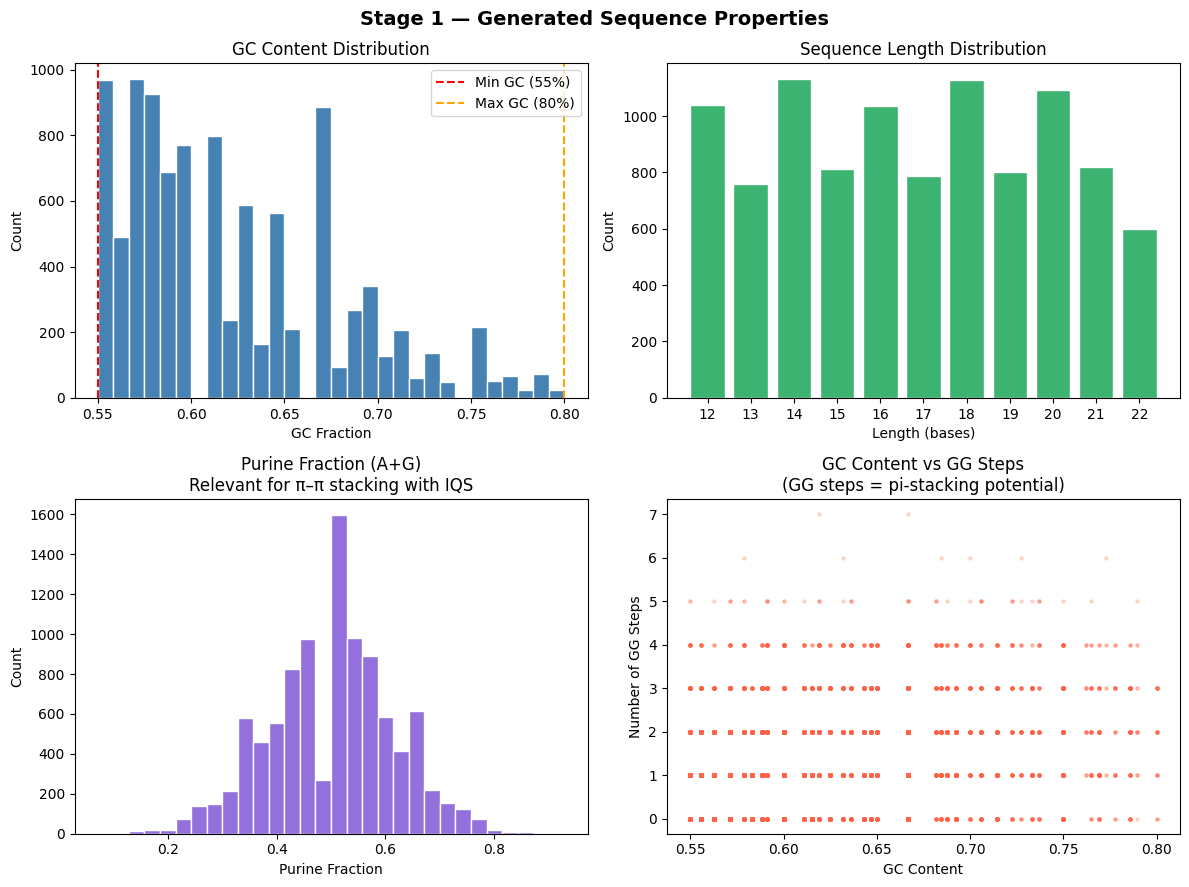


Plot saved to: C:\IQS-DNA2\generated_sequences\stage1_summary_plots.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle('Stage 1 — Generated Sequence Properties', fontsize=14, fontweight='bold')

# Plot 1: GC content distribution
axes[0, 0].hist(df['gc_content'], bins=30, color='steelblue', edgecolor='white')
axes[0, 0].axvline(MIN_GC, color='red',    linestyle='--', label=f'Min GC ({int(MIN_GC*100)}%)')
axes[0, 0].axvline(MAX_GC, color='orange', linestyle='--', label=f'Max GC ({int(MAX_GC*100)}%)')
axes[0, 0].set_title('GC Content Distribution')
axes[0, 0].set_xlabel('GC Fraction')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend()

# Plot 2: Sequence length distribution
length_counts = df['length'].value_counts().sort_index()
axes[0, 1].bar(length_counts.index, length_counts.values, color='mediumseagreen', edgecolor='white')
axes[0, 1].set_title('Sequence Length Distribution')
axes[0, 1].set_xlabel('Length (bases)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_xticks(range(MIN_LENGTH, MAX_LENGTH + 1))

# Plot 3: Purine fraction distribution
axes[1, 0].hist(df['purine_fraction'], bins=30, color='mediumpurple', edgecolor='white')
axes[1, 0].set_title('Purine Fraction (A+G)\nRelevant for π–π stacking with IQS')
axes[1, 0].set_xlabel('Purine Fraction')
axes[1, 0].set_ylabel('Count')

# Plot 4: GC content vs GG steps (scatter)
axes[1, 1].scatter(df['gc_content'], df['gg_steps'],
                   alpha=0.2, s=5, color='tomato')
axes[1, 1].set_title('GC Content vs GG Steps\n(GG steps = pi-stacking potential)')
axes[1, 1].set_xlabel('GC Content')
axes[1, 1].set_ylabel('Number of GG Steps')

plt.tight_layout()

# Save plot in same output folder
plot_path = os.path.join(output_dir, 'stage1_summary_plots.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"\nPlot saved to: {plot_path}")

## Cell 9 — What's Next

Stage 1 is complete. Your output files are in `./generated_sequences/`:
- `stage1_candidates.csv` — all sequences with their properties
- `stage1_summary_plots.png` — distribution plots

**➡ Next: Open `02_prefiltering.ipynb` for Stage 2**  
Stage 2 will load this CSV and apply scoring (Wallace Tm + IQS interaction potential) to reduce the 10,000 sequences down to the top 2,000.

In [9]:
print("Stage 1 complete.")
print(f"Output saved to: {output_path}")
print(f"Total sequences ready for Stage 2: {len(df)}")

Stage 1 complete.
Output saved to: C:\IQS-DNA2\generated_sequences\stage1_candidates.csv
Total sequences ready for Stage 2: 10000
